# 05 — NSIDCv6 spin-up sea-ice files against JRA55-FOSIRL

The sea-ice files provided by D. Comeau in `initial_conditions/Reanalysis_ICs/YYYYMMDD/`
(`mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spunup.YYYYMMDD.nc`, staged by `make_ice_ic.bash` as `ice/nsidc/`),
plotted beside the JRA55-FOSIRL (BruteForce archive) sea-ice restart of the same date where it exists (the 2015
dates; the archive ends in 2018, so the 2026 dates show the file alone).

1. Hemispheric ice area, extent, and ice and snow volume by date.
2. Maps of ice concentration, ice thickness, and snow on ice: the file, JRA55-FOSIRL, and their difference.

Figures and tables go to `DIAG_ROOT` when `SAVE_DIAG` is set.

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("util").resolve()))     # run from this directory
import clim_restart as cr
import ic_eval as ice
import seaice_check as sic

# Reload so edits to util/ take effect without restarting the kernel.
for module in (cr, ice, sic):
    importlib.reload(module)

ice.ensure_proj_data()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 80     # inline figures; saved figures use FIG_DPI

## Configuration

In [2]:
# ---- Files to plot (D. Comeau) -------------------------------------------------------------
ICE_ROOT    = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/Reanalysis_ICs")
ICE_PATTERN = "{tag}/mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spunup.{tag}.nc"   # tag: YYYYMMDD
DATES       = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01",
               "2026-02-01", "2026-05-01", "2026-08-01"]

# ---- JRA55-FOSIRL reference ----------------------------------------------------------------
SRC_ROOT   = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")   # read-only
SRC_PREFIX = "20251024_s2d_spinup"
CACHE_DIR  = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/cache")   # key fields of 01-03

# ---- Plots and output ----------------------------------------------------------------------
DIAG_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice")
SAVE_DIAG = True
FIG_DPI   = 150
FONTSIZE  = 10
LIMITS = {                              # state upper limit and difference limit per quantity
    "ice concentration": (1.0, 0.8),
    "ice thickness": (4.0, 2.0),
    "snow on ice": (0.5, 0.3),
}
UNITS = {"ice concentration": "fraction", "ice thickness": "m", "snow on ice": "m"}
FIELD_CMAPS = {"ice concentration": "Blues", "ice thickness": "cmo.dense", "snow on ice": "Blues"}

## Read the files

The JRA55-FOSIRL states come from the key-field cache of notebooks 01-03 (`CACHE_DIR/mpassi_MM-DD.npz`).

In [3]:
files, nsidc_ice, reference = {}, {}, {}
for date in DATES:
    year, mmdd = int(date[:4]), date[5:]
    files[date] = sic.ice_file(ICE_ROOT, ICE_PATTERN, date)
    nsidc_ice[date] = sic.read_state(files[date])
    archive = sic.archive_states(SRC_ROOT, SRC_PREFIX, mmdd, [year], CACHE_DIR)
    if year in archive:                 # JRA55-FOSIRL restart of the same date (2015)
        reference[date] = archive[year]

mesh = sic.read_mesh(files[DATES[0]])
descriptors = ice.build_mpassi_descriptors(files[DATES[0]])     # NH and SH polar projections of the mesh
ipd.display(pd.DataFrame({"file": {d: files[d].name for d in DATES},
                          "JRA55-FOSIRL": {d: "yes" if d in reference else "-" for d in DATES}}))

,file,JRA55-FOSIRL
2015-02-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,yes
2015-05-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,yes
2015-08-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,yes
2015-11-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,yes
2026-02-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,-
2026-05-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,-
2026-08-01,mpassi.IcoswISC30E3r5.iceArea_from_NSIDCv6_spu...,-


## 1. Hemispheric totals

Ice area (sum of concentration x cell area), extent (cells with concentration >= 0.15), and ice and snow
volume.

NH area  NH extent  NH ice volume  NH snow volume  SH area  SH extent  SH ice volume  SH snow volume
date       source                                                                                                               
2015-02-01 NSIDCv6 spin-up    14.03      14.60           3.34            0.06     0.03       0.00           0.04            0.00
           JRA55-FOSIRL       14.03      14.54          23.82            2.00     4.73       8.03           9.53            1.23
2015-05-01 NSIDCv6 spin-up    14.03      14.60           3.34            0.07     0.03       0.00           0.04            0.00
           JRA55-FOSIRL       13.07      14.41          29.91            2.65    10.27      11.10           9.83            1.78
2015-08-01 NSIDCv6 spin-up    14.04      14.62           3.34            0.06     0.03       0.00           0.04            0.00
           JRA55-FOSIRL        5.63       7.55          13.87            0.08    16.37      17.91          17.91            3.75
2015-11-01 NSIDCv6 spin-up    14.03      14.61           3.34            0.06     0.03       0.00           0.04            0.00
           JRA55-FOSIRL        8.21       8.52          11.42            0.59    15.25      18.09          21.48            4.72
2026-02-01 NSIDCv6 spin-up    14.03      14.61           3.34            0.06     0.03       0.00           0.04            0.00
2026-05-01 NSIDCv6 spin-up    14.03      14.62           3.34            0.06     0.03       0.00           0.04            0.00
2026-08-01 NSIDCv6 spin-up    14.04      14.61           3.34            0.06     0.03       0.00           0.04            0.00

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/data/hemispheric_totals.csv


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/hemispheric_totals.png


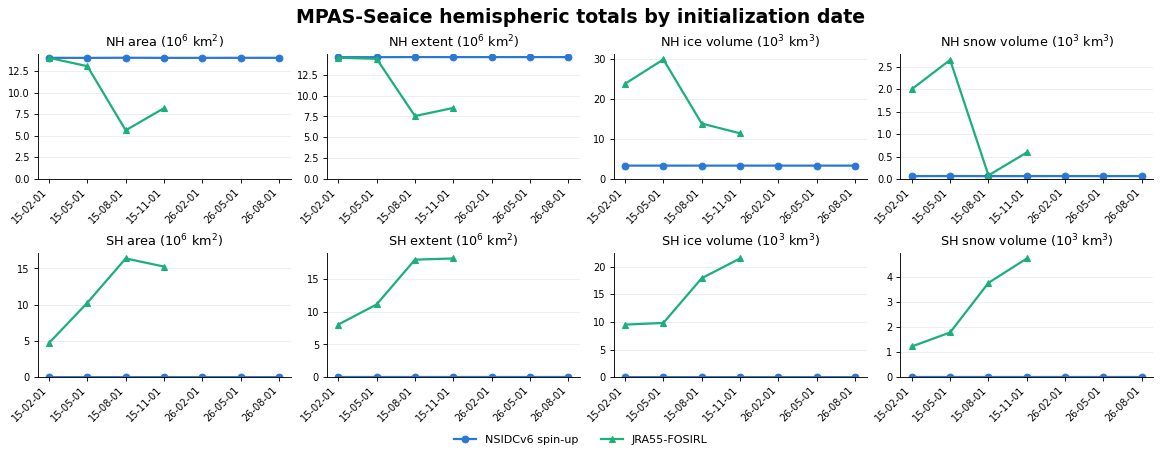

In [4]:
rows = []
for date in DATES:
    rows.append({"date": date, "source": "NSIDCv6 spin-up", **sic.hemispheric_totals(nsidc_ice[date], mesh)})
    if date in reference:
        rows.append({"date": date, "source": "JRA55-FOSIRL", **sic.hemispheric_totals(reference[date], mesh)})
totals = pd.DataFrame(rows)

ipd.display(totals.set_index(["date", "source"]).round(2))
ice.save_table(totals, "hemispheric_totals", DIAG_ROOT, SAVE_DIAG)
fig = sic.plot_totals(totals, fontsize=FONTSIZE)
ice.save_fig(fig, "hemispheric_totals", DIAG_ROOT, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

## 2. Maps

One figure per quantity and hemisphere, one row per date. Columns: the NSIDCv6 spin-up file, the JRA55-FOSIRL
restart of the same date, and the file minus JRA55-FOSIRL (2015 dates only). Gray: land.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/nh_ice_concentration.png


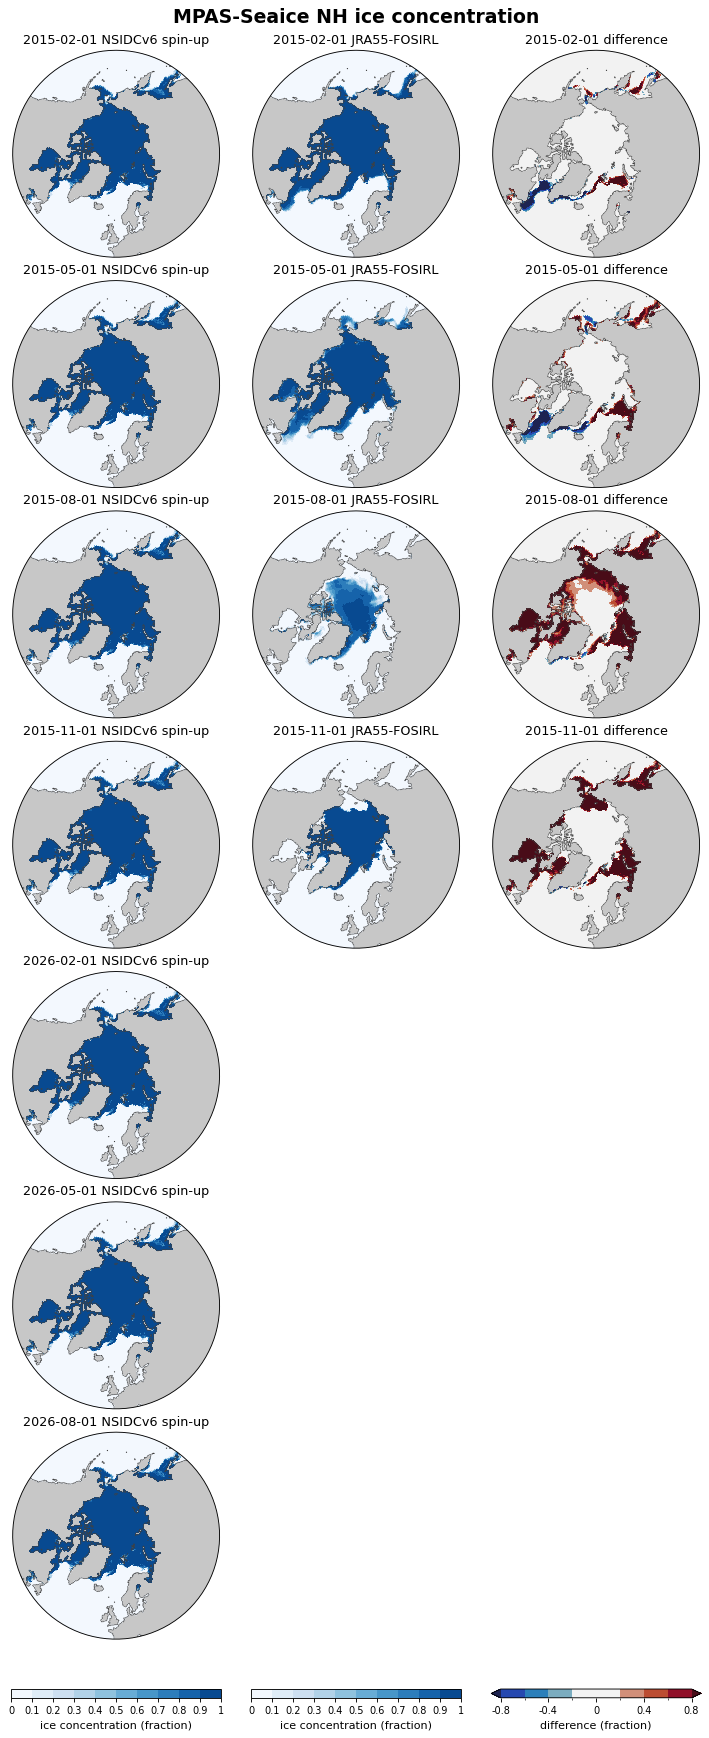

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/sh_ice_concentration.png


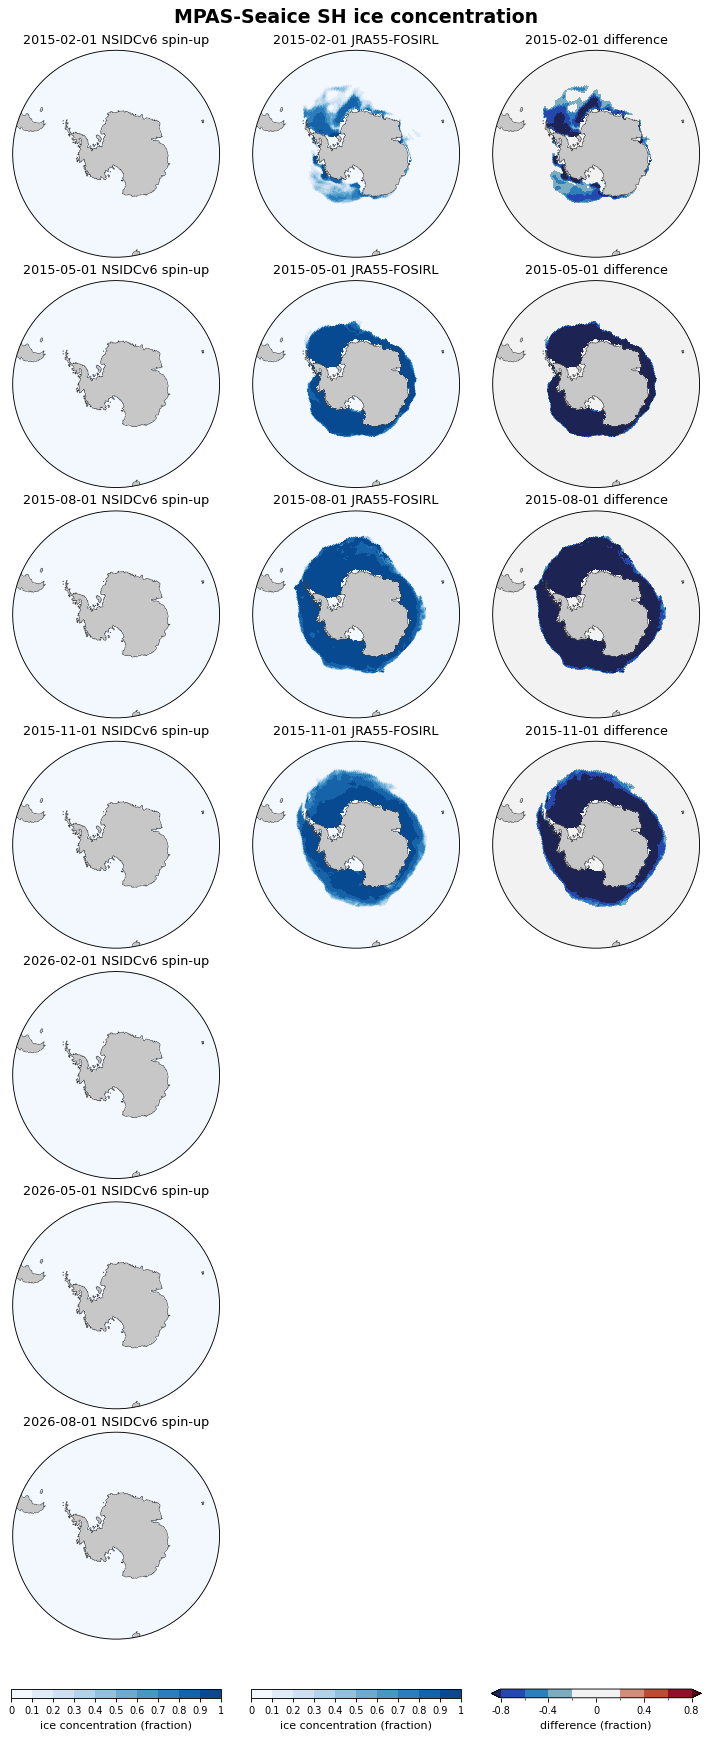

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/nh_ice_thickness.png


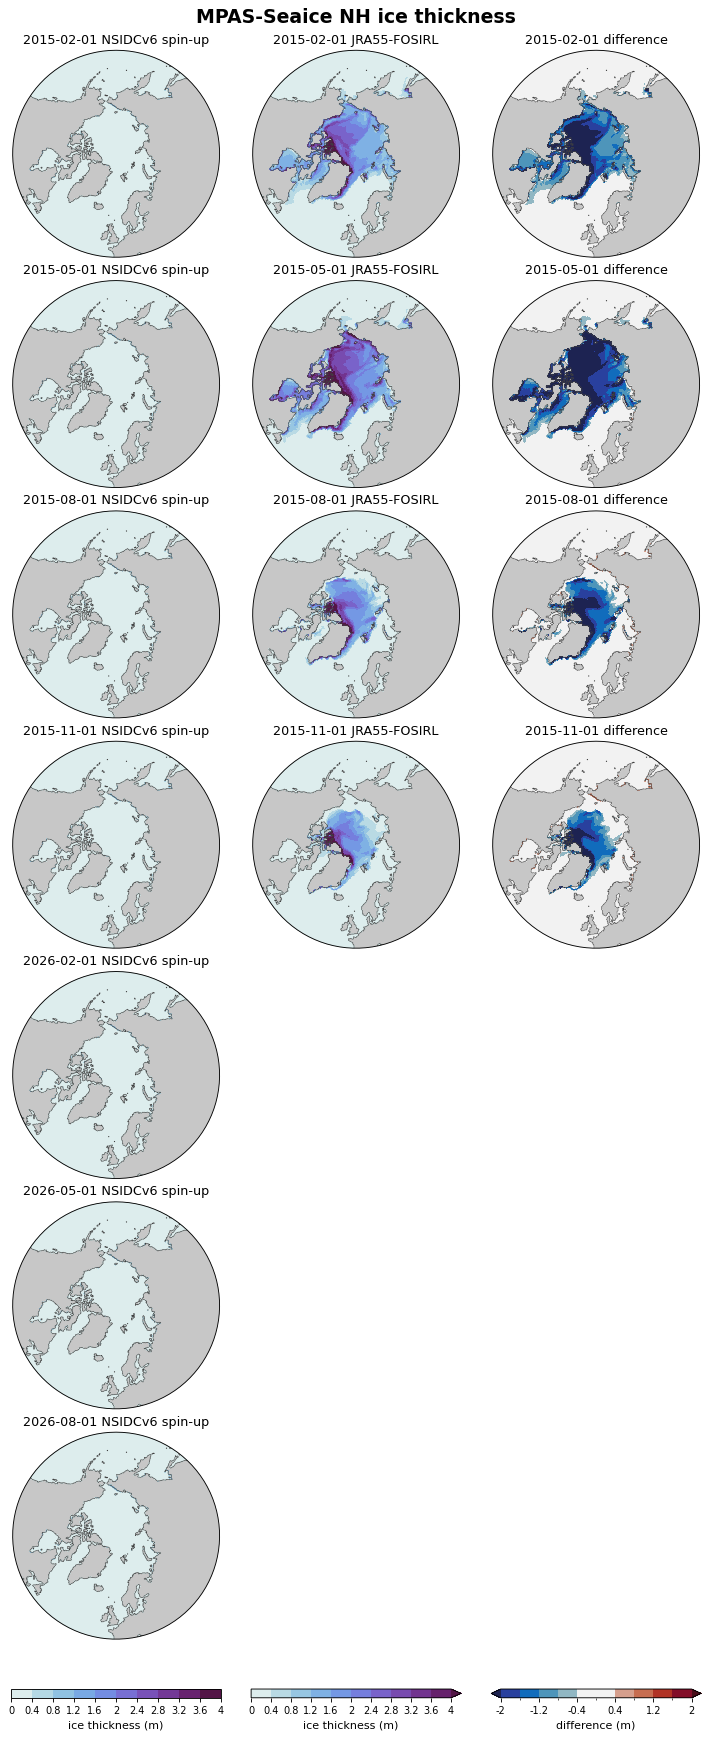

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/sh_ice_thickness.png


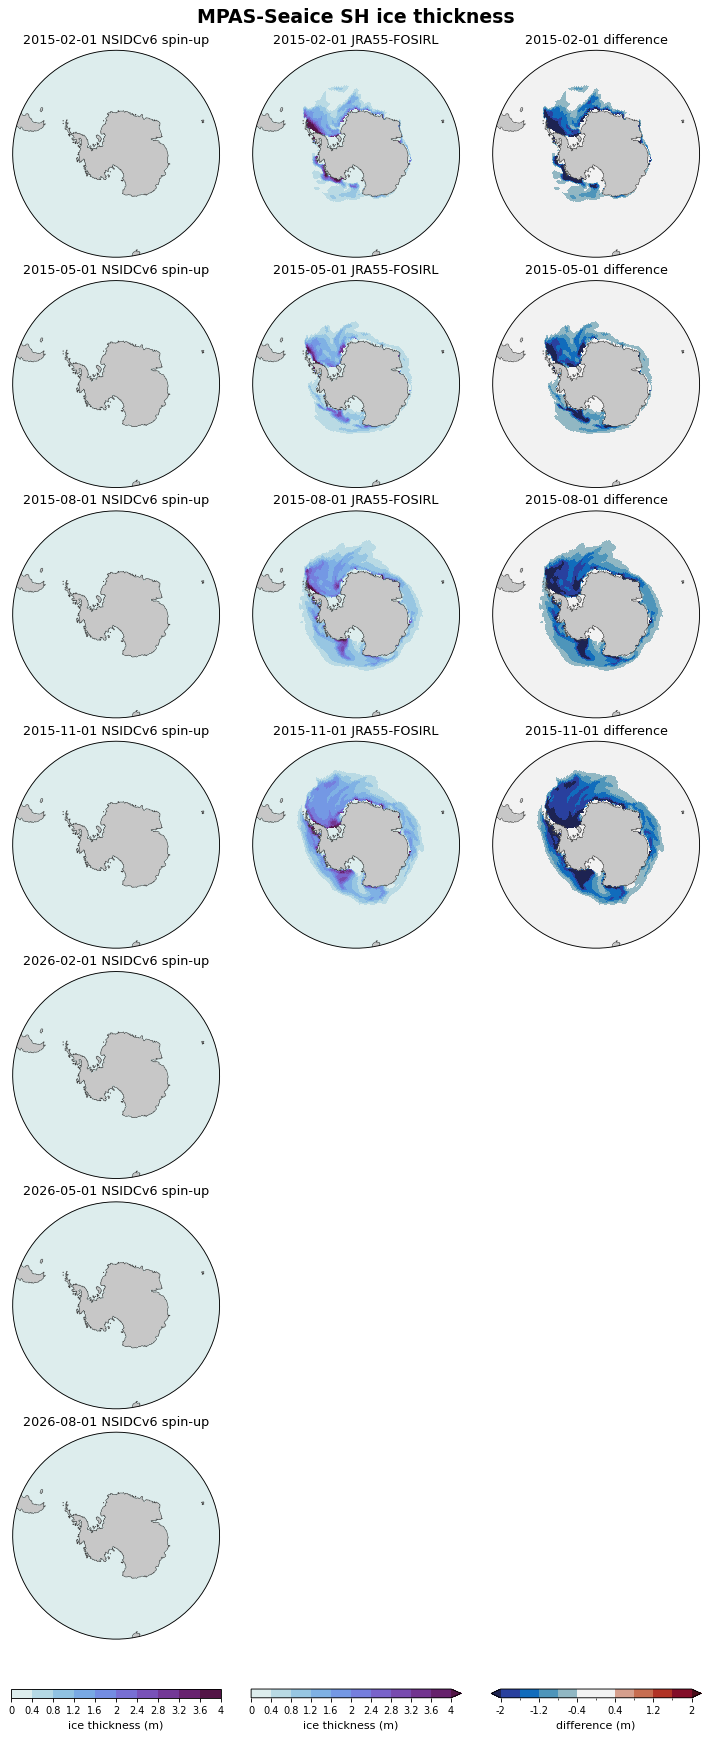

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/nh_snow_on_ice.png


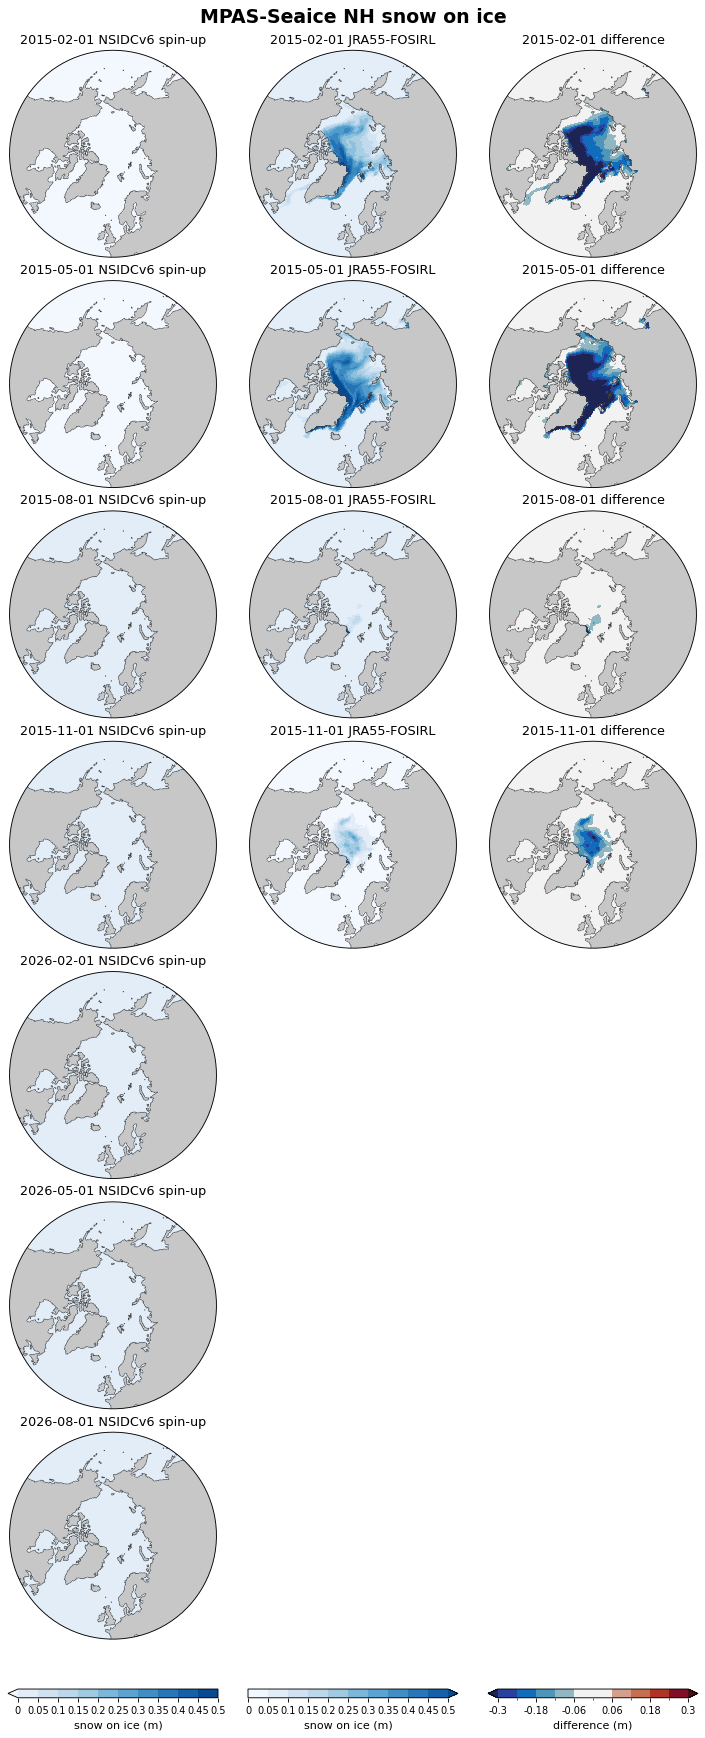

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/reanalysis_ice/figure/sh_snow_on_ice.png


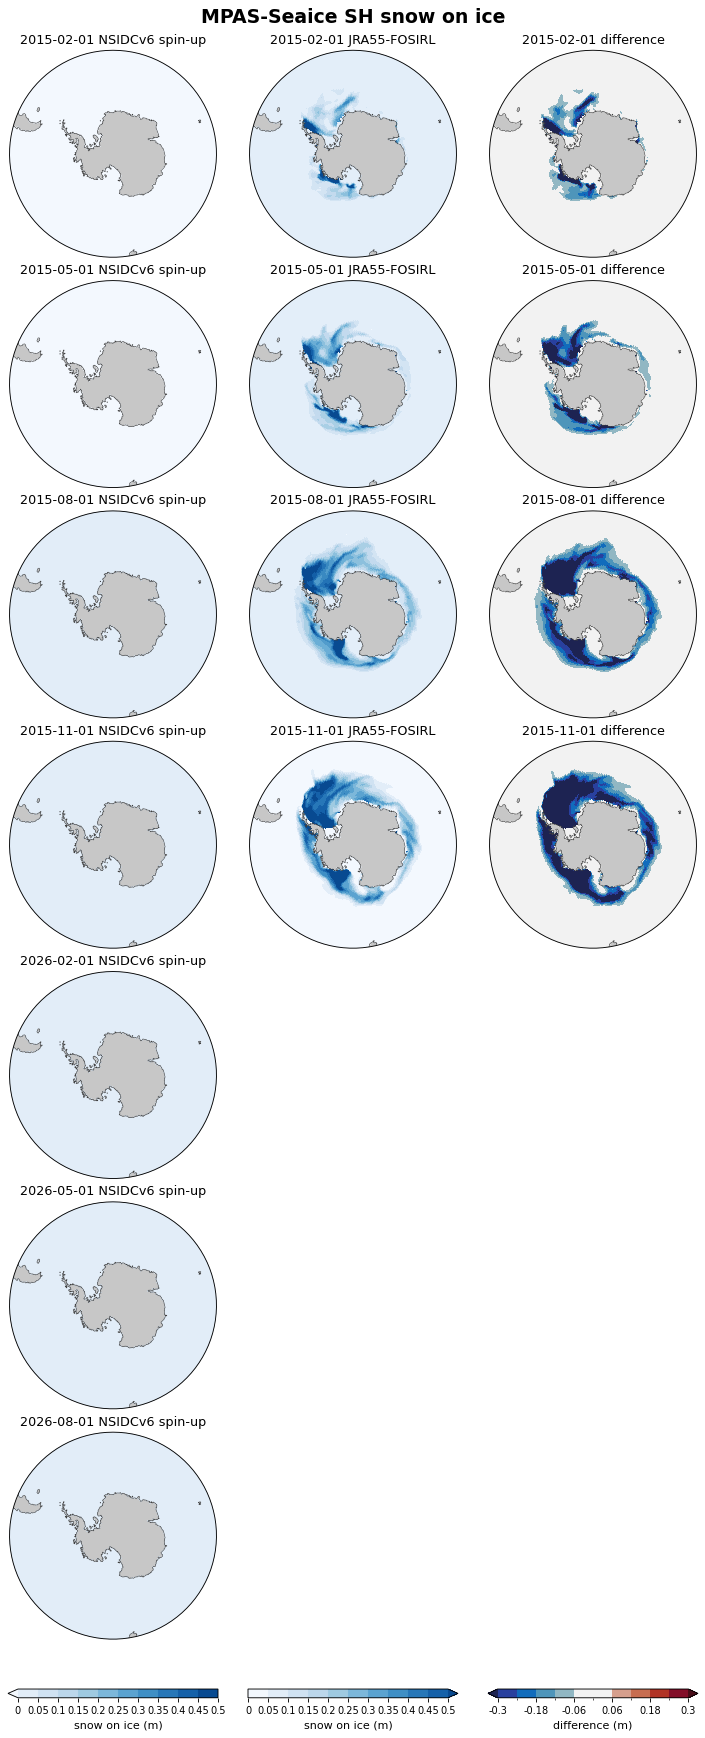

In [5]:
for q in sic.QUANTITIES:
    hi, dl = LIMITS[q]
    for hemi in sic.HEMISPHERES:
        rows = [(hemi, [
            (f"{date} NSIDCv6 spin-up", nsidc_ice[date][q], FIELD_CMAPS[q], 0.0, hi, f"{q} ({UNITS[q]})"),
            (f"{date} JRA55-FOSIRL", reference[date][q], FIELD_CMAPS[q], 0.0, hi, f"{q} ({UNITS[q]})")
            if date in reference else None,
            (f"{date} difference", nsidc_ice[date][q] - reference[date][q], ice.DIFF_CMAP, -dl, dl,
             f"difference ({UNITS[q]})") if date in reference else None,
        ]) for date in DATES]
        fig = sic.plot_mpassi_rows(rows, descriptors, f"MPAS-Seaice {hemi} {q}", fontsize=FONTSIZE,
                                   panel_size=(3.0, 3.0))
        ice.save_fig(fig, f"{hemi.lower()}_{ice.slugify(q)}", DIAG_ROOT, SAVE_DIAG, dpi=FIG_DPI)
        plt.show()